
# Consumption–Saving RL — Final Multi-Seed Experiment

최종 결과용 노트북입니다.

## Algorithms
- Standard DQN + validation checkpoint selection
- Discrete PPO + validation checkpoint selection

## Training seeds
`[0, 1, 2, 3, 4]`

## Evaluation
- 같은 validation paths로 checkpoint 선택
- validation과 독립적인 같은 test paths로 최종 평가
- 5개 training seed의 test utility에 대해 t-based 95% CI 계산
- Random / Fixed 50% / DP-Matched도 같은 test setup으로 비교

`Run all`에서는 heavy training이 실행되지 않습니다.


In [1]:

# 0. Setup
import sys, subprocess, importlib, random, copy, shutil
from pathlib import Path
from collections import deque

try:
    import gymnasium as gym
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gymnasium"])
    import gymnasium as gym

import sympy
_sympy_printing = importlib.import_module("sympy.printing")
if not hasattr(sympy, "printing"):
    sympy.printing = _sympy_printing

try:
    import stable_baselines3
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "stable-baselines3"])
    import stable_baselines3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from gymnasium import spaces

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor

print("Python", sys.version.split()[0])
print("PyTorch", torch.__version__)
print("Gymnasium", gym.__version__)
print("SB3", stable_baselines3.__version__)


Python 3.13.18
PyTorch 2.11.0+cpu
Gymnasium 1.4.0
SB3 2.9.2


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:

# 1. Calibration
R = 1.00985
BETA = 0.9703
SIGMA = 2.0

Y_HIGH = 1.0
Y_LOW = 0.472

P_INCOME = np.array([
    [0.9393, 0.0607],
    [0.3920, 0.6080]
], dtype=np.float64)

SAVING_SHARES = np.arange(0.0, 1.0, 0.05, dtype=np.float64)

A_MAX = 4.5
N_ASSETS = 500

TRAIN_SEEDS = [0, 1, 2, 3, 4]

VALIDATION_SEED = 54321
TEST_SEED = 10000

VALIDATION_EPISODES = 512
VALIDATION_HORIZON = 300

TEST_EPISODES = 2000
TEST_HORIZON = 500


In [3]:

# 2. Environment

class ConsumptionSavingEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, random_initial_state=False):
        super().__init__()
        self.random_initial_state = random_initial_state
        self.action_space = spaces.Discrete(len(SAVING_SHARES))
        self.observation_space = spaces.Box(
            low=np.array([0.0, Y_LOW], dtype=np.float32),
            high=np.array([np.inf, Y_HIGH], dtype=np.float32),
            dtype=np.float32
        )
        self.asset = None
        self.income_state = None

    def _obs(self):
        income = Y_HIGH if self.income_state == 0 else Y_LOW
        return np.array([self.asset, income], dtype=np.float32)

    def _utility(self, c):
        if np.isclose(SIGMA, 1.0):
            return float(np.log(c))
        return float(c ** (1.0 - SIGMA) / (1.0 - SIGMA))

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = options or {}

        if "initial_asset" in options:
            self.asset = float(options["initial_asset"])
        elif self.random_initial_state:
            self.asset = float(self.np_random.uniform(0.0, 4.5))
        else:
            self.asset = 1.0

        if "initial_income_state" in options:
            self.income_state = int(options["initial_income_state"])
        elif self.random_initial_state:
            self.income_state = int(self.np_random.integers(0, 2))
        else:
            self.income_state = 0

        return self._obs(), {}

    def step(self, action):
        z = float(SAVING_SHARES[int(action)])
        income = Y_HIGH if self.income_state == 0 else Y_LOW
        cash = R * self.asset + income
        next_asset = z * cash
        consumption = (1.0 - z) * cash
        reward = self._utility(consumption)

        next_income_state = int(
            self.np_random.choice(2, p=P_INCOME[self.income_state])
        )

        self.asset = next_asset
        self.income_state = next_income_state

        return self._obs(), reward, False, False, {"saving_share": z}


class PPOObservationWrapper(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = spaces.Box(
            low=np.array([0.0, Y_LOW], dtype=np.float32),
            high=np.array([np.inf, Y_HIGH], dtype=np.float32),
            dtype=np.float32
        )

    def observation(self, observation):
        obs = np.asarray(observation, dtype=np.float32).copy()
        obs[0] /= 4.5
        return obs


def make_ppo_training_env():
    env = ConsumptionSavingEnv(random_initial_state=True)
    env = PPOObservationWrapper(env)
    env = gym.wrappers.TimeLimit(env, max_episode_steps=200)
    return Monitor(env)


In [4]:

# 3. DP-Matched oracle

def solve_dp_matched(tolerance=1e-10, max_iterations=5000):
    asset_grid = np.linspace(0.0, A_MAX, N_ASSETS)
    V = np.zeros((N_ASSETS, 2), dtype=np.float64)
    policy_share = np.zeros_like(V)

    for iteration in range(max_iterations):
        V_new = np.empty_like(V)

        for income_state, income in [(0, Y_HIGH), (1, Y_LOW)]:
            cash = R * asset_grid + income
            Q = np.full((N_ASSETS, len(SAVING_SHARES)), -np.inf)

            for j, z in enumerate(SAVING_SHARES):
                next_asset = z * cash
                consumption = (1.0 - z) * cash

                feasible = (consumption > 1e-12) & (next_asset <= A_MAX)

                V_H = np.interp(next_asset, asset_grid, V[:, 0])
                V_L = np.interp(next_asset, asset_grid, V[:, 1])

                expected_future = (
                    P_INCOME[income_state, 0] * V_H
                    + P_INCOME[income_state, 1] * V_L
                )

                if np.isclose(SIGMA, 1.0):
                    utility = np.log(consumption)
                else:
                    utility = consumption ** (1.0 - SIGMA) / (1.0 - SIGMA)

                q = utility + BETA * expected_future
                q[~feasible] = -np.inf
                Q[:, j] = q

            best_idx = np.argmax(Q, axis=1)
            V_new[:, income_state] = Q[np.arange(N_ASSETS), best_idx]
            policy_share[:, income_state] = SAVING_SHARES[best_idx]

        diff = np.max(np.abs(V_new - V))
        V = V_new

        if diff < tolerance:
            print("DP converged:", iteration + 1)
            break

    return asset_grid, V, policy_share

asset_grid_m, V_dp_matched, policy_share_matched = solve_dp_matched()

dp_bellman_value = np.interp(1.0, asset_grid_m, V_dp_matched[:, 0])
print("DP-Matched Bellman value:", dp_bellman_value)


DP converged: 769
DP-Matched Bellman value: -36.23960733972141


In [5]:

# 4. Common evaluation helpers

def utility_vectorized(c):
    if np.isclose(SIGMA, 1.0):
        return np.log(c)
    return c ** (1.0 - SIGMA) / (1.0 - SIGMA)


def summarize_returns(returns):
    returns = np.asarray(returns, dtype=np.float64)
    mean = returns.mean()
    std = returns.std(ddof=1)
    se = std / np.sqrt(len(returns))
    ci = 1.96 * se
    return {
        "mean_utility": mean,
        "std_utility": std,
        "ci_lower": mean - ci,
        "ci_upper": mean + ci
    }


def simulate_policy(action_function, n_episodes=TEST_EPISODES,
                    horizon=TEST_HORIZON, seed=TEST_SEED):
    rng = np.random.default_rng(seed)

    assets = np.ones(n_episodes)
    income_states = np.zeros(n_episodes, dtype=int)
    returns = np.zeros(n_episodes)
    discount = 1.0

    for _ in range(horizon):
        incomes = np.where(income_states == 0, Y_HIGH, Y_LOW)
        z = action_function(assets, income_states, incomes)

        cash = R * assets + incomes
        consumption = (1.0 - z) * cash
        returns += discount * utility_vectorized(consumption)
        assets = z * cash

        p_low = np.where(
            income_states == 0,
            P_INCOME[0, 1],
            P_INCOME[1, 1]
        )

        income_states = (
            rng.random(n_episodes) < p_low
        ).astype(int)

        discount *= BETA

    return summarize_returns(returns)


def evaluate_fixed_policy(z):
    return simulate_policy(
        lambda assets, income_states, incomes: np.full(len(assets), z)
    )


def evaluate_dp_policy():
    def dp_action(assets, income_states, incomes):
        idx = np.clip(
            np.searchsorted(asset_grid_m, assets),
            1,
            len(asset_grid_m) - 1
        )
        left = asset_grid_m[idx - 1]
        right = asset_grid_m[idx]
        nearest = np.where(
            np.abs(assets - right) < np.abs(assets - left),
            idx,
            idx - 1
        )
        return policy_share_matched[nearest, income_states]

    return simulate_policy(dp_action)


fixed_50_baseline = evaluate_fixed_policy(0.50)
dp_test = evaluate_dp_policy()

print("Fixed 50%:", fixed_50_baseline)
print("DP-Matched:", dp_test)


Fixed 50%: {'mean_utility': np.float64(-36.74520228639539), 'std_utility': np.float64(2.1544866408884276), 'ci_lower': np.float64(-36.839626826673964), 'ci_upper': np.float64(-36.650777746116816)}
DP-Matched: {'mean_utility': np.float64(-36.25482128180089), 'std_utility': np.float64(1.9429592265372282), 'ci_lower': np.float64(-36.33997522439863), 'ci_upper': np.float64(-36.16966733920316)}


In [6]:

# 5. DQN definitions

def normalize_state(state):
    state = np.asarray(state, dtype=np.float32).copy()
    state[..., 0] /= 4.5
    return state


class ReplayBuffer:
    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)

    def put(self, state, action, reward, next_state):
        self.buffer.append((
            normalize_state(state),
            int(action),
            float(reward),
            normalize_state(next_state)
        ))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states = zip(*batch)

        return (
            torch.tensor(np.asarray(states), dtype=torch.float32),
            torch.tensor(actions, dtype=torch.long),
            torch.tensor(rewards, dtype=torch.float32),
            torch.tensor(np.asarray(next_states), dtype=torch.float32)
        )

    def __len__(self):
        return len(self.buffer)


class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, len(SAVING_SHARES))

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


def get_dqn_policy(q_network):
    q_network.eval()
    policy = np.zeros((len(asset_grid_m), 2))

    for income_state, income in [(0, Y_HIGH), (1, Y_LOW)]:
        states = np.column_stack([
            asset_grid_m,
            np.full(len(asset_grid_m), income)
        ]).astype(np.float32)

        states[:, 0] /= 4.5

        with torch.no_grad():
            actions = (
                q_network(torch.tensor(states, dtype=torch.float32))
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        policy[:, income_state] = SAVING_SHARES[actions]

    return policy


def evaluate_dqn(q_network, n_episodes=TEST_EPISODES,
                 horizon=TEST_HORIZON, seed=TEST_SEED):

    q_network.eval()

    def dqn_action(assets, income_states, incomes):
        states = np.column_stack([assets, incomes]).astype(np.float32)
        states[:, 0] /= 4.5

        with torch.no_grad():
            actions = (
                q_network(torch.tensor(states, dtype=torch.float32))
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        return SAVING_SHARES[actions]

    return simulate_policy(
        dqn_action,
        n_episodes=n_episodes,
        horizon=horizon,
        seed=seed
    )


In [7]:

# 6. DQN trainer with checkpointing

def train_dqn_final(training_seed,
                    total_steps=100_000,
                    eval_interval=5_000):

    random.seed(training_seed)
    np.random.seed(training_seed)
    torch.manual_seed(training_seed)

    rng = np.random.default_rng(training_seed)

    env = ConsumptionSavingEnv(random_initial_state=False)

    q = QNetwork()
    target_q = QNetwork()
    target_q.load_state_dict(q.state_dict())
    target_q.eval()

    optimizer = optim.Adam(q.parameters(), lr=1e-3)
    replay_buffer = ReplayBuffer(100_000)

    def sample_start():
        return float(rng.uniform(0.0, 4.5)), int(rng.integers(0, 2))

    a0, y0 = sample_start()
    state, _ = env.reset(
        seed=training_seed,
        options={"initial_asset": a0, "initial_income_state": y0}
    )

    episode_step = 0

    best_val = -np.inf
    best_step = None
    best_state_dict = None
    history = []

    for step in range(1, total_steps + 1):
        fraction = min((step - 1) / 25_000, 1.0)
        epsilon = 1.0 + fraction * (0.05 - 1.0)

        if rng.random() < epsilon:
            action = int(rng.integers(0, len(SAVING_SHARES)))
        else:
            s = torch.tensor(
                normalize_state(state),
                dtype=torch.float32
            ).unsqueeze(0)

            with torch.no_grad():
                action = int(q(s).argmax(dim=1).item())

        next_state, reward, _, _, _ = env.step(action)

        replay_buffer.put(state, action, reward, next_state)

        state = next_state
        episode_step += 1

        if episode_step >= 200:
            a0, y0 = sample_start()
            state, _ = env.reset(
                options={"initial_asset": a0, "initial_income_state": y0}
            )
            episode_step = 0

        if len(replay_buffer) >= 1_000:
            states, actions, rewards, next_states = replay_buffer.sample(64)

            q_selected = (
                q(states)
                .gather(1, actions.unsqueeze(1))
                .squeeze(1)
            )

            with torch.no_grad():
                max_next_q = target_q(next_states).max(dim=1).values
                target = rewards + BETA * max_next_q

            loss = F.mse_loss(q_selected, target)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(q.parameters(), max_norm=10.0)
            optimizer.step()

        if step % 500 == 0:
            target_q.load_state_dict(q.state_dict())

        if step % eval_interval == 0:
            val = evaluate_dqn(
                q,
                n_episodes=VALIDATION_EPISODES,
                horizon=VALIDATION_HORIZON,
                seed=VALIDATION_SEED
            )

            policy = get_dqn_policy(q)
            err = np.abs(policy - policy_share_matched)

            history.append({
                "seed": training_seed,
                "step": step,
                "validation_utility": val["mean_utility"],
                "policy_mae": err.mean()
            })

            if val["mean_utility"] > best_val:
                best_val = val["mean_utility"]
                best_step = step
                best_state_dict = {
                    k: v.detach().cpu().clone()
                    for k, v in q.state_dict().items()
                }

    best_q = QNetwork()
    best_q.load_state_dict(best_state_dict)
    best_q.eval()

    return best_q, pd.DataFrame(history), best_step


In [8]:

# 7. PPO helpers

def get_ppo_policy(model):
    policy = np.zeros((len(asset_grid_m), 2))

    for income_state, income in [(0, Y_HIGH), (1, Y_LOW)]:
        obs = np.column_stack([
            asset_grid_m / 4.5,
            np.full(len(asset_grid_m), income)
        ]).astype(np.float32)

        actions, _ = model.predict(obs, deterministic=True)
        actions = np.asarray(actions).reshape(-1).astype(int)

        policy[:, income_state] = SAVING_SHARES[actions]

    return policy


def evaluate_ppo(model, n_episodes=TEST_EPISODES,
                 horizon=TEST_HORIZON, seed=TEST_SEED):

    def ppo_action(assets, income_states, incomes):
        obs = np.column_stack([
            assets / 4.5,
            incomes
        ]).astype(np.float32)

        actions, _ = model.predict(obs, deterministic=True)
        actions = np.asarray(actions).reshape(-1).astype(int)

        return SAVING_SHARES[actions]

    return simulate_policy(
        ppo_action,
        n_episodes=n_episodes,
        horizon=horizon,
        seed=seed
    )


def train_ppo_final(training_seed,
                    total_timesteps=100_000,
                    chunk_size=10_000):

    model = PPO(
        "MlpPolicy",
        make_ppo_training_env(),
        learning_rate=3e-4,
        n_steps=2048,
        batch_size=64,
        gamma=BETA,
        gae_lambda=0.95,
        clip_range=0.2,
        ent_coef=0.0,
        verbose=0,
        seed=training_seed,
        device="auto"
    )

    best_val = -np.inf
    best_step = None
    best_parameters = None
    history = []

    completed = 0

    while completed < total_timesteps:
        current_chunk = min(chunk_size, total_timesteps - completed)

        model.learn(
            total_timesteps=current_chunk,
            reset_num_timesteps=False
        )

        completed += current_chunk

        val = evaluate_ppo(
            model,
            n_episodes=VALIDATION_EPISODES,
            horizon=VALIDATION_HORIZON,
            seed=VALIDATION_SEED
        )

        policy = get_ppo_policy(model)
        err = np.abs(policy - policy_share_matched)

        history.append({
            "seed": training_seed,
            "step": completed,
            "validation_utility": val["mean_utility"],
            "policy_mae": err.mean()
        })

        if val["mean_utility"] > best_val:
            best_val = val["mean_utility"]
            best_step = completed
            best_parameters = copy.deepcopy(model.get_parameters())

    best_model = PPO(
        "MlpPolicy",
        make_ppo_training_env(),
        learning_rate=3e-4,
        n_steps=2048,
        batch_size=64,
        gamma=BETA,
        gae_lambda=0.95,
        clip_range=0.2,
        ent_coef=0.0,
        verbose=0,
        seed=training_seed,
        device="auto"
    )

    best_model.set_parameters(best_parameters)

    return best_model, pd.DataFrame(history), best_step


In [9]:

# 8. Summary helpers

def seed_ci(values):
    values = np.asarray(values, dtype=np.float64)
    n = len(values)

    mean = values.mean()
    sd = values.std(ddof=1)
    se = sd / np.sqrt(n)

    critical = student_t.ppf(0.975, df=n - 1)
    half_width = critical * se

    return mean, sd, mean - half_width, mean + half_width


def cev_percent(policy_value, benchmark_value):
    ratio = benchmark_value / policy_value
    k = ratio ** (1.0 / (1.0 - SIGMA))
    return (k - 1.0) * 100.0



# Final heavy experiment

**계산부하: 매우 무거움**

- DQN: 5 seeds × 100k steps
- PPO: 5 seeds × 100k timesteps
- seed별 best checkpoint 선택
- 같은 test paths에서 비교
- seed-level 95% CI 계산
- seed별 모델과 CSV 저장

기존 단일 100k 실험을 약 10번 수행하는 규모입니다.

`Run all`에서는 실행되지 않습니다.



[DQN seed 0]
best=15000, utility=-36.6248, MAE=0.0693

[DQN seed 1]
best=75000, utility=-36.5261, MAE=0.0423

[DQN seed 2]
best=30000, utility=-36.3992, MAE=0.0569

[DQN seed 3]
best=90000, utility=-36.4945, MAE=0.0505

[DQN seed 4]
best=60000, utility=-36.4687, MAE=0.0436

[PPO seed 0]
best=100000, utility=-36.7269, MAE=0.1237

[PPO seed 1]
best=30000, utility=-36.7317, MAE=0.2322

[PPO seed 2]
best=10000, utility=-36.7583, MAE=0.0900

[PPO seed 3]
best=20000, utility=-36.7583, MAE=0.2052

[PPO seed 4]
best=20000, utility=-36.8856, MAE=0.2731


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,algorithm,training_seed,best_step,test_mean_utility,test_path_ci_lower,test_path_ci_upper,policy_mae,exact_agreement,within_5pp,within_10pp,cev_percent_vs_dp
0,DQN,0,15000,-36.624764,-36.721799,-36.527729,0.06925,0.152,0.614,0.858,1.020395
1,DQN,1,75000,-36.526101,-36.611950,-36.440253,0.04235,0.402,0.830,0.939,0.748259
2,DQN,2,30000,-36.399165,-36.487703,-36.310628,0.05685,0.219,0.648,0.996,0.398138
3,DQN,3,90000,-36.494529,-36.581948,-36.407110,0.05050,0.301,0.722,0.971,0.661175
4,DQN,4,60000,-36.468735,-36.560631,-36.376839,0.04360,0.393,0.779,0.956,0.590029
5,PPO,0,100000,-36.726899,-36.815707,-36.638092,0.12375,0.096,0.285,0.463,1.302111
6,PPO,1,30000,-36.731674,-36.830252,-36.633096,0.23220,0.043,0.119,0.201,1.315280
7,PPO,2,10000,-36.758281,-36.855333,-36.661229,0.08995,0.158,0.473,0.836,1.388670
8,PPO,3,20000,-36.758281,-36.855333,-36.661229,0.20520,0.041,0.127,0.233,1.388670
9,PPO,4,20000,-36.885577,-36.987654,-36.783500,0.27310,0.030,0.091,0.154,1.739784



FINAL SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Mean Utility,Seed SD,95% CI Lower,95% CI Upper,Mean Policy MAE,Mean Exact,Mean Within 5pp,Mean Within 10pp,Mean CEV % vs DP
0,Fixed 50%,-36.745202,NaN,-36.839627,-36.650778,NaN,NaN,NaN,NaN,1.352595
1,DP-Matched,-36.254821,NaN,-36.339975,-36.169667,0.00000,1.0000,1.0000,1.0000,0.000000
2,DQN,-36.502659,0.082745,-36.605400,-36.399917,0.05251,0.2934,0.7186,0.9440,0.683599
3,PPO,-36.772143,0.065070,-36.852937,-36.691348,0.18484,0.0736,0.2190,0.3774,1.426903


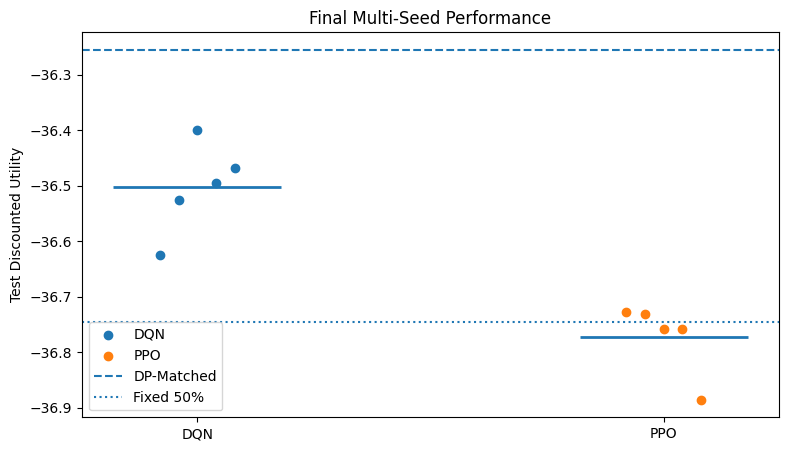

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


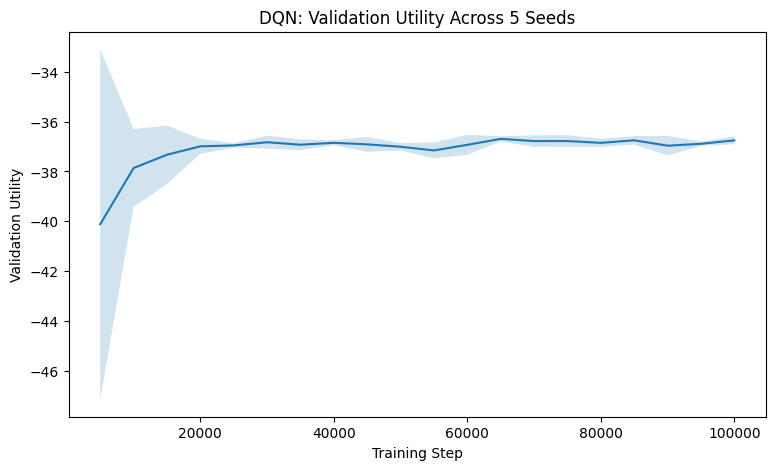

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


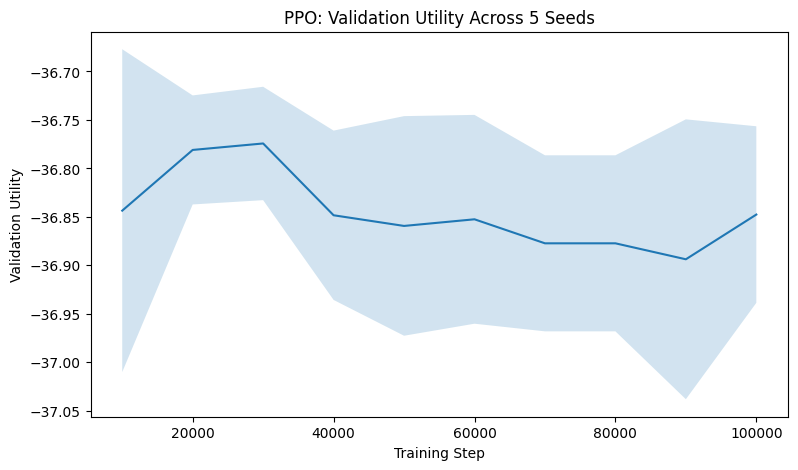

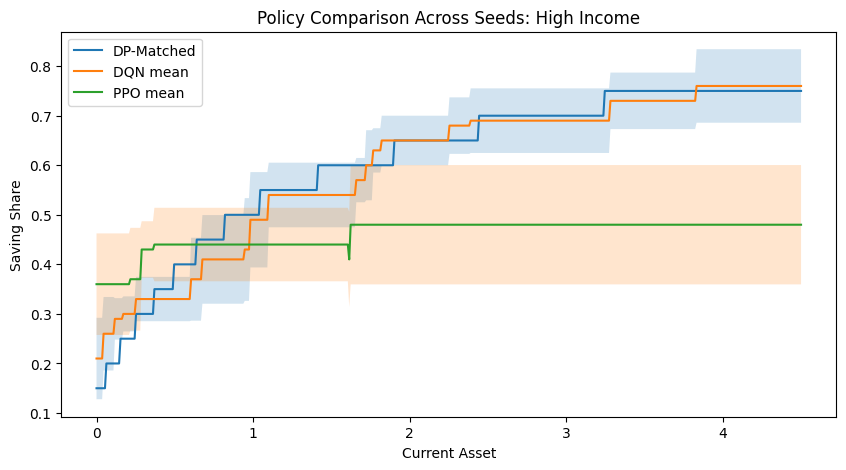

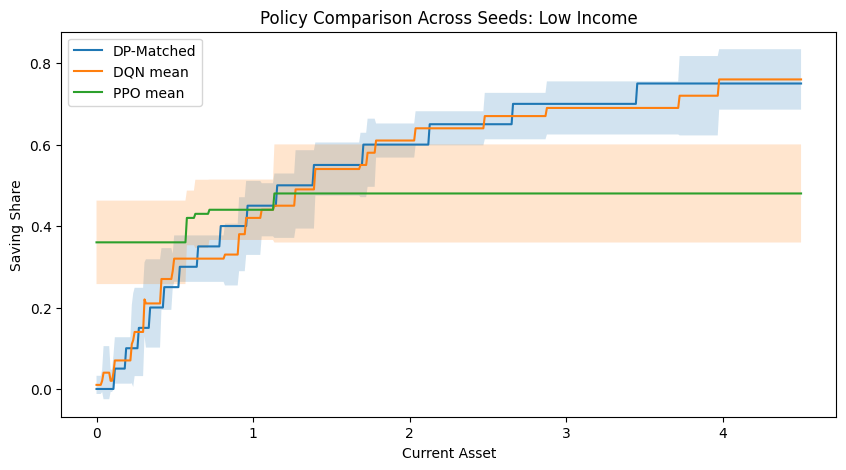


Results folder: /content/rl_final_multiseed
Model ZIP: /content/rl_final_models.zip


In [11]:

# 9. HEAVY FINAL CELL

RUN_FINAL_EXPERIMENT = True

if not RUN_FINAL_EXPERIMENT:
    print(
        "Setup complete.\n"
        "Change RUN_FINAL_EXPERIMENT = True and rerun THIS CELL ONLY."
    )

else:
    OUTPUT_DIR = Path("/content/rl_final_multiseed")
    MODEL_DIR = OUTPUT_DIR / "models"

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    seed_rows = []
    dqn_histories = []
    ppo_histories = []
    dqn_policies = []
    ppo_policies = []

    # ---------- DQN ----------
    for seed in TRAIN_SEEDS:
        print(f"\n[DQN seed {seed}]")

        best_model, history, best_step = train_dqn_final(seed)

        test = evaluate_dqn(best_model)
        policy = get_dqn_policy(best_model)
        err = np.abs(policy - policy_share_matched)

        seed_rows.append({
            "algorithm": "DQN",
            "training_seed": seed,
            "best_step": best_step,
            "test_mean_utility": test["mean_utility"],
            "test_path_ci_lower": test["ci_lower"],
            "test_path_ci_upper": test["ci_upper"],
            "policy_mae": err.mean(),
            "exact_agreement": np.mean(
                np.isclose(policy, policy_share_matched)
            ),
            "within_5pp": np.mean(err <= 0.0500001),
            "within_10pp": np.mean(err <= 0.1000001),
            "cev_percent_vs_dp": cev_percent(
                test["mean_utility"],
                dp_test["mean_utility"]
            )
        })

        dqn_histories.append(history)
        dqn_policies.append(policy)

        torch.save(
            best_model.state_dict(),
            MODEL_DIR / f"dqn_best_seed_{seed}.pt"
        )

        pd.DataFrame(seed_rows).to_csv(
            OUTPUT_DIR / "seed_results_partial.csv",
            index=False
        )

        print(
            f"best={best_step}, "
            f"utility={test['mean_utility']:.4f}, "
            f"MAE={err.mean():.4f}"
        )

    # ---------- PPO ----------
    for seed in TRAIN_SEEDS:
        print(f"\n[PPO seed {seed}]")

        best_model, history, best_step = train_ppo_final(seed)

        test = evaluate_ppo(best_model)
        policy = get_ppo_policy(best_model)
        err = np.abs(policy - policy_share_matched)

        seed_rows.append({
            "algorithm": "PPO",
            "training_seed": seed,
            "best_step": best_step,
            "test_mean_utility": test["mean_utility"],
            "test_path_ci_lower": test["ci_lower"],
            "test_path_ci_upper": test["ci_upper"],
            "policy_mae": err.mean(),
            "exact_agreement": np.mean(
                np.isclose(policy, policy_share_matched)
            ),
            "within_5pp": np.mean(err <= 0.0500001),
            "within_10pp": np.mean(err <= 0.1000001),
            "cev_percent_vs_dp": cev_percent(
                test["mean_utility"],
                dp_test["mean_utility"]
            )
        })

        ppo_histories.append(history)
        ppo_policies.append(policy)

        best_model.save(
            str(MODEL_DIR / f"ppo_best_seed_{seed}")
        )

        pd.DataFrame(seed_rows).to_csv(
            OUTPUT_DIR / "seed_results_partial.csv",
            index=False
        )

        print(
            f"best={best_step}, "
            f"utility={test['mean_utility']:.4f}, "
            f"MAE={err.mean():.4f}"
        )

    # ---------- Tables ----------
    seed_results = pd.DataFrame(seed_rows)
    seed_results.to_csv(
        OUTPUT_DIR / "final_seed_results.csv",
        index=False
    )

    display(seed_results)

    summary_rows = []

    for algorithm in ["DQN", "PPO"]:
        subset = seed_results[
            seed_results["algorithm"] == algorithm
        ]

        mean_u, sd_u, ci_l, ci_u = seed_ci(
            subset["test_mean_utility"].values
        )

        summary_rows.append({
            "Model": algorithm,
            "Mean Utility": mean_u,
            "Seed SD": sd_u,
            "95% CI Lower": ci_l,
            "95% CI Upper": ci_u,
            "Mean Policy MAE": subset["policy_mae"].mean(),
            "Mean Exact": subset["exact_agreement"].mean(),
            "Mean Within 5pp": subset["within_5pp"].mean(),
            "Mean Within 10pp": subset["within_10pp"].mean(),
            "Mean CEV % vs DP": subset["cev_percent_vs_dp"].mean()
        })

    baseline_rows = [
        {
            "Model": "Fixed 50%",
            "Mean Utility": fixed_50_baseline["mean_utility"],
            "Seed SD": np.nan,
            "95% CI Lower": fixed_50_baseline["ci_lower"],
            "95% CI Upper": fixed_50_baseline["ci_upper"],
            "Mean Policy MAE": np.nan,
            "Mean Exact": np.nan,
            "Mean Within 5pp": np.nan,
            "Mean Within 10pp": np.nan,
            "Mean CEV % vs DP": cev_percent(
                fixed_50_baseline["mean_utility"],
                dp_test["mean_utility"]
            )
        },
        {
            "Model": "DP-Matched",
            "Mean Utility": dp_test["mean_utility"],
            "Seed SD": np.nan,
            "95% CI Lower": dp_test["ci_lower"],
            "95% CI Upper": dp_test["ci_upper"],
            "Mean Policy MAE": 0.0,
            "Mean Exact": 1.0,
            "Mean Within 5pp": 1.0,
            "Mean Within 10pp": 1.0,
            "Mean CEV % vs DP": 0.0
        }
    ]

    final_summary = pd.concat(
        [
            pd.DataFrame(baseline_rows),
            pd.DataFrame(summary_rows)
        ],
        ignore_index=True
    )

    final_summary.to_csv(
        OUTPUT_DIR / "final_summary.csv",
        index=False
    )

    print("\nFINAL SUMMARY")
    display(final_summary)

    # ---------- Histories ----------
    dqn_history_all = pd.concat(dqn_histories, ignore_index=True)
    ppo_history_all = pd.concat(ppo_histories, ignore_index=True)

    dqn_history_all.to_csv(
        OUTPUT_DIR / "dqn_validation_history.csv",
        index=False
    )

    ppo_history_all.to_csv(
        OUTPUT_DIR / "ppo_validation_history.csv",
        index=False
    )

    # ---------- Figure: seed utilities ----------
    plt.figure(figsize=(9, 5))

    for i, algorithm in enumerate(["DQN", "PPO"]):
        vals = seed_results.loc[
            seed_results["algorithm"] == algorithm,
            "test_mean_utility"
        ].values

        offsets = np.linspace(-0.08, 0.08, len(vals))

        plt.scatter(
            np.full(len(vals), i) + offsets,
            vals,
            label=algorithm
        )

        plt.hlines(
            vals.mean(),
            i - 0.18,
            i + 0.18,
            linewidth=2
        )

    plt.axhline(
        dp_test["mean_utility"],
        linestyle="--",
        label="DP-Matched"
    )

    plt.axhline(
        fixed_50_baseline["mean_utility"],
        linestyle=":",
        label="Fixed 50%"
    )

    plt.xticks([0, 1], ["DQN", "PPO"])
    plt.ylabel("Test Discounted Utility")
    plt.title("Final Multi-Seed Performance")
    plt.legend()
    plt.show()

    # ---------- Figure: validation curves ----------
    for algorithm, history_df in [
        ("DQN", dqn_history_all),
        ("PPO", ppo_history_all)
    ]:
        pivot = history_df.pivot(
            index="step",
            columns="seed",
            values="validation_utility"
        )

        mean_curve = pivot.mean(axis=1)
        sd_curve = pivot.std(axis=1, ddof=1)

        plt.figure(figsize=(9, 5))
        plt.plot(mean_curve.index, mean_curve.values)
        plt.fill_between(
            mean_curve.index,
            (mean_curve - sd_curve).values,
            (mean_curve + sd_curve).values,
            alpha=0.2
        )
        plt.xlabel("Training Step")
        plt.ylabel("Validation Utility")
        plt.title(f"{algorithm}: Validation Utility Across 5 Seeds")
        plt.show()

    # ---------- Figure: mean policies ----------
    dqn_stack = np.stack(dqn_policies, axis=0)
    ppo_stack = np.stack(ppo_policies, axis=0)

    for income_state, label in [(0, "High Income"), (1, "Low Income")]:
        plt.figure(figsize=(10, 5))

        plt.plot(
            asset_grid_m,
            policy_share_matched[:, income_state],
            label="DP-Matched"
        )

        dqn_mean = dqn_stack[:, :, income_state].mean(axis=0)
        dqn_sd = dqn_stack[:, :, income_state].std(axis=0, ddof=1)

        plt.plot(asset_grid_m, dqn_mean, label="DQN mean")
        plt.fill_between(
            asset_grid_m,
            dqn_mean - dqn_sd,
            dqn_mean + dqn_sd,
            alpha=0.2
        )

        ppo_mean = ppo_stack[:, :, income_state].mean(axis=0)
        ppo_sd = ppo_stack[:, :, income_state].std(axis=0, ddof=1)

        plt.plot(asset_grid_m, ppo_mean, label="PPO mean")
        plt.fill_between(
            asset_grid_m,
            ppo_mean - ppo_sd,
            ppo_mean + ppo_sd,
            alpha=0.2
        )

        plt.xlabel("Current Asset")
        plt.ylabel("Saving Share")
        plt.title(f"Policy Comparison Across Seeds: {label}")
        plt.legend()
        plt.show()

    # ---------- ZIP models ----------
    zip_path = shutil.make_archive(
        "/content/rl_final_models",
        "zip",
        MODEL_DIR
    )

    print("\nResults folder:", OUTPUT_DIR)
    print("Model ZIP:", zip_path)
